In [1]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e10/train.csv
/kaggle/input/competitions/playground-series-s6e10/test.csv


In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import os, gc
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import TargetEncoder
from sklearn.metrics import roc_auc_score
import warnings
warnings.filterwarnings('ignore')
os.environ['XGBOOST_WARN_PREDICT_FALLBACK'] = '0'



%matplotlib inline

In [3]:
path = '/kaggle/input/competitions/playground-series-s6e10'
df_train = pd.read_csv(path+'/train.csv')
df_test = pd.read_csv(path+'/test.csv')
df_submission = pd.read_csv(path+'/sample_submission.csv')

TARGET = 'satisfaction'
ID = 'id'
# EXPERIMENT_NAME = "XGBoost"
df_train[TARGET] = df_train[TARGET].astype(int)
NJ_SEED = 42

for df in [df_train, df_test]:
    df['Arrival Delay in Minutes'] = df['Arrival Delay in Minutes'].fillna(df['Departure Delay in Minutes'])

CAT_FEATURES = ['Gender', 'Customer Type', 'Type of Travel', 'Class']
RATING_COLS = [
    'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 
    'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 
    'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness'
]

# 2.  FEATURE ENGINEERING

In [7]:
# 🧮 Generating Domain Features & Pairs
for df in [df_train, df_test]:
    df['biz_elite_nj'] = ((df['Type of Travel'] == 'Business travel') & (df['Class'] == 'Business')).astype(np.int8)
    df['Wifi_Booking_pair'] = df['Inflight wifi service'].astype(str) + "_" + df['Ease of Online booking'].astype(str)
    df['Wifi_Time_pair']    = df['Inflight wifi service'].astype(str) + "_" + df['Departure/Arrival time convenient'].astype(str)
    df['Boarding_Wifi_pair']= df['Online boarding'].astype(str) + "_" + df['Inflight wifi service'].astype(str)
    df['Class_Travel_pair'] = df['Class'].astype(str) + "_" + df['Type of Travel'].astype(str)
    df['Cust_Travel_pair']  = df['Customer Type'].astype(str) + "_" + df['Type of Travel'].astype(str)
    df['Class_Cust_pair']   = df['Class'].astype(str) + "_" + df['Customer Type'].astype(str)
    df['Class_Wifi_pair']     = df['Class'].astype(str) + "_" + df['Inflight wifi service'].astype(str)
    df['Class_Boarding_pair'] = df['Class'].astype(str) + "_" + df['Online boarding'].astype(str)
    df['Travel_Wifi_pair']    = df['Type of Travel'].astype(str) + "_" + df['Inflight wifi service'].astype(str)
    df['Travel_Boarding_pair']= df['Type of Travel'].astype(str) + "_" + df['Online boarding'].astype(str)
    df['Seat_Ent_pair']       = df['Seat comfort'].astype(str) + "_" + df['Inflight entertainment'].astype(str)
    df['Route_Class_pair'] = df['Flight Distance'].astype(str) + "_" + df['Class'].astype(str)
    df['Route_Travel_pair'] = df['Flight Distance'].astype(str) + "_" + df['Type of Travel'].astype(str)

INTERACTION_COLS = [
    'Wifi_Booking_pair', 'Wifi_Time_pair', 'Boarding_Wifi_pair', 'Class_Travel_pair', 'Cust_Travel_pair', 
    'Class_Cust_pair', 'Class_Wifi_pair', 'Class_Boarding_pair', 'Travel_Wifi_pair', 'Travel_Boarding_pair', 
    'Seat_Ent_pair', 'Route_Class_pair', 'Route_Travel_pair'
]

# 🔢 Extracting  Digits
DIGIT_MAP = {'Age': [0, 1], 'Flight Distance': [0, 1, 2, 3], 'Departure Delay in Minutes': [1], 'Arrival Delay in Minutes': [1]}
digit_feats_nj = [] 
for c, powers in DIGIT_MAP.items():
    for k in powers:
        col_name = f"{c}_digit{k}"
        df_train[col_name] = (df_train[c].fillna(0) // (10**k) % 10).astype(np.int8)
        df_test[col_name] = (df_test[c].fillna(0) // (10**k) % 10).astype(np.int8)
        digit_feats_nj.append(col_name)

# ✈️ Extracting Route Profiles based on Flight Distance
for df in [df_train, df_test]:
    df['Route_ID'] = df['Flight Distance'].astype(int)

route_counts = pd.concat([df_train['Route_ID'], df_test['Route_ID']], ignore_index=True).value_counts()
for df in [df_train, df_test]:
    df['Route_Freq'] = df['Route_ID'].map(route_counts).astype(np.int32)

route_profile_cols = ['Age', 'Departure Delay in Minutes'] + RATING_COLS
route_profile = df_train.groupby('Route_ID')[route_profile_cols].mean()
route_profile.columns = [f"Route_Mean_{c.replace(' ', '_').replace('/', '_')}" for c in route_profile.columns]
route_profile = route_profile.reset_index()

df_train = df_train.merge(route_profile, on="Route_ID", how="left")
df_test  = df_test.merge(route_profile,  on="Route_ID", how="left")

for c in route_profile.columns:
    if c == "Route_ID": continue
    df_train[c] = df_train[c].fillna(df_train[c].mean())
    df_test[c]  = df_test[c].fillna(df_train[c].mean())

df_train.drop(columns=['Route_ID'], inplace=True)
df_test.drop(columns=['Route_ID'], inplace=True)

# Setup Encoding
TARGET_ENCODE_COLS = CAT_FEATURES + RATING_COLS + digit_feats_nj + INTERACTION_COLS

num_to_cat_cols = []
for c in ['Age', 'Flight Distance']: 
    cat_name = f"{c}_cat"
    df_train[cat_name] = df_train[c].fillna(-1).astype(str)
    df_test[cat_name] = df_test[c].fillna(-1).astype(str)
    num_to_cat_cols.append(cat_name)

TARGET_ENCODE_COLS.extend(num_to_cat_cols)

for df in [df_train, df_test]:
    for col in CAT_FEATURES + digit_feats_nj:
        df[col] = df[col].astype(str)
    for col in RATING_COLS:
        df[col] = "Rating_" + df[col].astype(str)

# 📊 Applying Frequency Encoding
combined_nj = pd.concat([df_train, df_test], ignore_index=True)
for col in TARGET_ENCODE_COLS:
    freq_mapping = combined_nj[col].value_counts(normalize=True).to_dict()
    df_train[f"{col}_FE"] = df_train[col].map(freq_mapping).astype(np.float32)
    df_test[f"{col}_FE"]  = df_test[col].map(freq_mapping).astype(np.float32)
del combined_nj; gc.collect()

# Hardcoded Pruning List
FEATURES_TO_DROP = [
    'Departure Delay in Minutes_digit1_FE', 'Departure Delay in Minutes_digit1_TE_auto',
    'Arrival Delay in Minutes_digit1_FE', 'Arrival Delay in Minutes_digit1_TE_auto',
    'Departure Delay in Minutes', 'Flight Distance_digit3_FE', 'Flight Distance_digit1_FE',
    'Age_digit0_FE', 'Flight Distance_digit0_FE', 'Flight Distance_digit2_FE'
]

In [9]:
df_train

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Class_Cust_pair_FE,Class_Wifi_pair_FE,Class_Boarding_pair_FE,Travel_Wifi_pair_FE,Travel_Boarding_pair_FE,Seat_Ent_pair_FE,Route_Class_pair_FE,Route_Travel_pair_FE,Age_cat_FE,Flight Distance_cat_FE
0,0,36,694,Rating_4,Rating_4,Rating_4,3,Rating_1,Rating_4,Rating_1,...,0.359224,0.076735,0.094671,0.038736,0.056338,0.071492,0.000527,0.000345,0.022100,0.000674
1,1,56,651,Rating_5,Rating_5,Rating_5,5,Rating_5,Rating_4,Rating_4,...,0.426533,0.079811,0.197423,0.105471,0.245176,0.069587,0.001349,0.002527,0.018407,0.004160
2,2,31,1371,Rating_3,Rating_4,Rating_2,5,Rating_3,Rating_3,Rating_3,...,0.359224,0.143177,0.136935,0.096820,0.086142,0.117335,0.000315,0.000222,0.016230,0.000539
3,3,10,1616,Rating_3,Rating_5,Rating_3,3,Rating_3,Rating_3,Rating_3,...,0.359224,0.143177,0.136935,0.096820,0.086142,0.117335,0.000283,0.000259,0.004326,0.000953
4,4,23,481,Rating_3,Rating_4,Rating_3,4,Rating_5,Rating_3,Rating_5,...,0.108644,0.143177,0.136935,0.166667,0.127787,0.174994,0.000480,0.000468,0.023795,0.000738
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699630,699630,57,612,Rating_2,Rating_1,Rating_1,1,Rating_1,Rating_3,Rating_3,...,0.359224,0.144391,0.136935,0.171270,0.127787,0.021392,0.003005,0.002806,0.018999,0.004509
699631,699631,30,862,Rating_2,Rating_2,Rating_2,3,Rating_4,Rating_2,Rating_4,...,0.108644,0.144391,0.123992,0.171270,0.093184,0.195023,0.006208,0.005242,0.021711,0.009577
699632,699632,49,3148,Rating_5,Rating_5,Rating_5,5,Rating_4,Rating_4,Rating_4,...,0.426533,0.079811,0.197423,0.105471,0.245176,0.069587,0.000069,0.000069,0.023008,0.000069
699633,699633,61,679,Rating_5,Rating_2,Rating_2,2,Rating_5,Rating_4,Rating_4,...,0.359224,0.029046,0.094671,0.105471,0.245176,0.069587,0.004528,0.003600,0.005906,0.006286


In [10]:
df_train.duplicated().sum()

np.int64(0)

In [11]:
df_train.isna().sum()

id                                   0
Age                                  0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
                                    ..
Seat_Ent_pair_FE                     0
Route_Class_pair_FE                  0
Route_Travel_pair_FE                 0
Age_cat_FE                           0
Flight Distance_cat_FE               0
Length: 101, dtype: int64

<Axes: >

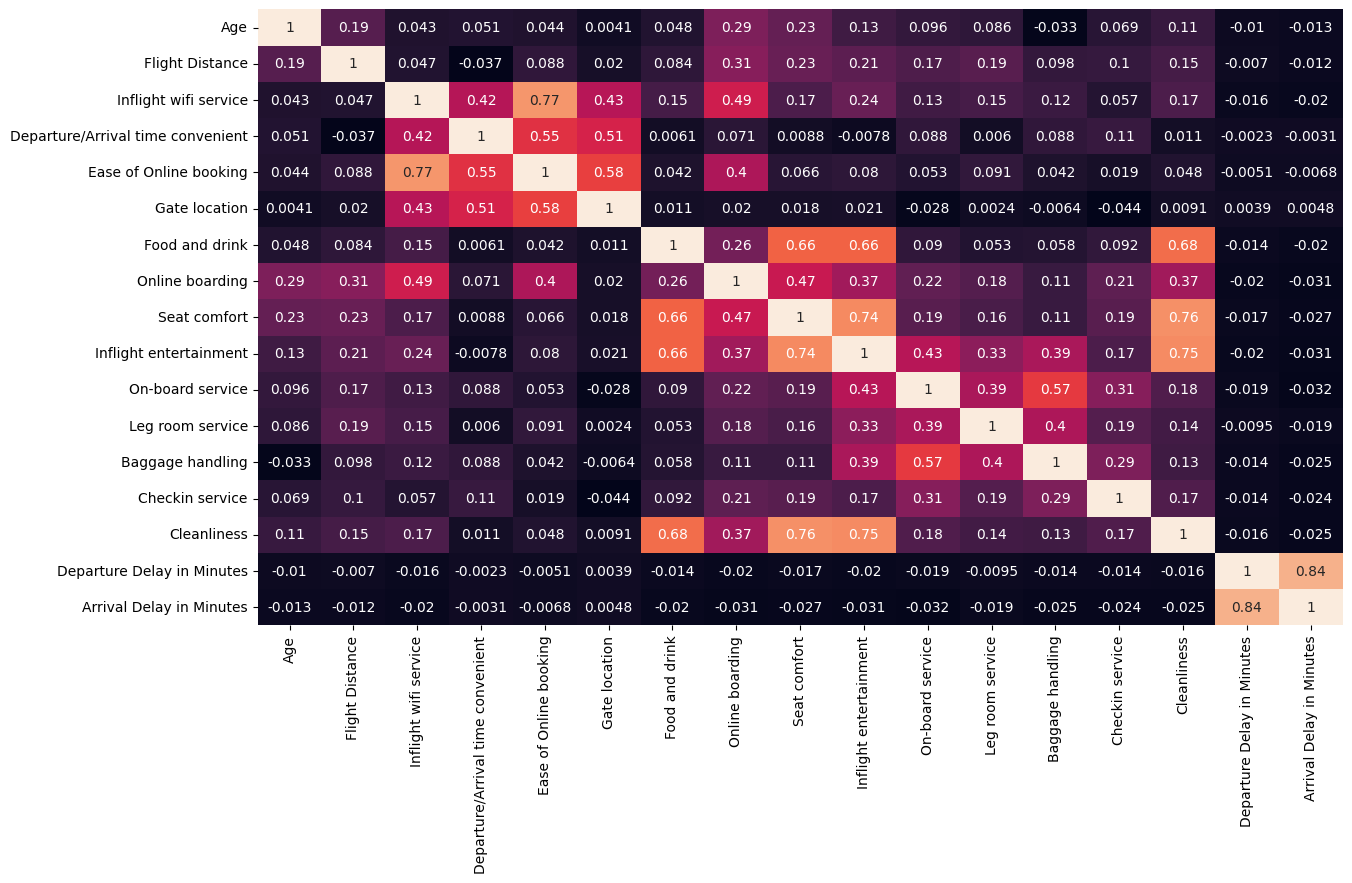

In [7]:
plt.figure(figsize=(14, 8))
sns.heatmap(df_train.iloc[:, 1:].select_dtypes(include=np.number).corr(), annot=True, cbar=False)

In [8]:
df_train.select_dtypes(include=np.number)

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699630,699630,57,612,2,1,1,1,1,3,3,2,2,2,2,2,4,0,0.0
699631,699631,30,862,2,2,2,3,4,2,4,4,2,5,4,2,4,24,34.0
699632,699632,49,3148,5,5,5,5,4,4,4,5,5,5,5,5,5,0,0.0
699633,699633,61,679,5,2,2,2,5,4,4,5,4,5,5,5,1,0,0.0


In [9]:
df_train.select_dtypes(exclude=np.number)

,Gender,Customer Type,Type of Travel,Class,satisfaction
0,Female,Loyal Customer,Personal Travel,Eco,False
1,Male,Loyal Customer,Business travel,Business,True
2,Female,Loyal Customer,Personal Travel,Eco,False
3,Male,Loyal Customer,Personal Travel,Eco,False
4,Female,disloyal Customer,Business travel,Eco,False
...,...,...,...,...,...
699630,Female,Loyal Customer,Business travel,Eco,False
699631,Female,disloyal Customer,Business travel,Eco,False
699632,Male,Loyal Customer,Business travel,Business,True
699633,Female,Loyal Customer,Business travel,Eco,True


In [10]:
df_train.describe().T

,count,mean,std,min,25%,50%,75%,max
id,699635.0,349817.000000,201967.372129,0.0,174908.5,349817.0,524725.5,699634.0
Age,699635.0,39.001928,13.800943,7.0,27.0,40.0,50.0,85.0
Flight Distance,699635.0,1353.778702,954.422566,67.0,631.0,954.0,1814.0,4983.0
Inflight wifi service,699635.0,2.778722,1.280419,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,699635.0,3.156210,1.475390,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,699635.0,2.813240,1.329550,0.0,2.0,3.0,4.0,5.0
Gate location,699635.0,3.013734,1.254014,0.0,2.0,3.0,4.0,5.0
Food and drink,699635.0,3.265644,1.300202,0.0,2.0,3.0,4.0,5.0
Online boarding,699635.0,3.364156,1.288538,0.0,2.0,4.0,4.0,5.0
Seat comfort,699635.0,3.568950,1.275333,0.0,3.0,4.0,5.0,5.0


In [11]:
df_train['satisfaction'].value_counts()

satisfaction
False    389296
True     310339
Name: count, dtype: int64

In [12]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   6996

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelBinarizer, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import RobustScaler
import time
from sklearn.model_selection import StratifiedKFold

In [ ]:
FEATURES = [c for c in train.columns if c not in [ID, TARGET, 'Arrival_Delay_missing'] + TARGET_ENCODE_COLS]
X = train[FEATURES + TARGET_ENCODE_COLS]
y = train[TARGET]
X_test = test[FEATURES + TARGET_ENCODE_COLS]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=NJ_SEED)
oof_preds = np.zeros(len(train))
test_preds = np.zeros(len(test))
fold_scores = []
best_iters = []

xgb_params = {
        'n_estimators': 10000,
        'learning_rate': 0.005,
        'max_depth': 9,
        'subsample': 0.85,
        'colsample_bytree': 0.4,
        'colsample_bynode': 0.65,
        'min_child_weight': 30,
        'reg_lambda': 2.5,
        'max_bin': 256,
        'tree_method': 'hist',
        'device': 'cuda',       
        'eval_metric': 'auc',
        'early_stopping_rounds': 200,
        'random_state': NJ_SEED
    }

for fold, (train_idx, valid_idx) in enumerate(skf.split(X, y), 1):
    X_train, y_train = X.iloc[train_idx].copy(), y.iloc[train_idx]
    X_valid, y_valid = X.iloc[valid_idx].copy(), y.iloc[valid_idx]
    X_test_fold = X_test.copy()

    te_auto = TargetEncoder(shuffle=True, cv=5, smooth='auto', random_state=NJ_SEED)
    X_train_enc = te_auto.fit_transform(X_train[TARGET_ENCODE_COLS], y_train)
    X_valid_enc = te_auto.transform(X_valid[TARGET_ENCODE_COLS])
    X_test_enc  = te_auto.transform(X_test_fold[TARGET_ENCODE_COLS])

    for i, col in enumerate(TARGET_ENCODE_COLS):
        X_train[f"{col}_TE_auto"] = X_train_enc[:, i].astype(np.float32)
        X_valid[f"{col}_TE_auto"] = X_valid_enc[:, i].astype(np.float32)
        X_test_fold[f"{col}_TE_auto"] = X_test_enc[:, i].astype(np.float32)
        X_train.drop(columns=[col], inplace=True)
        X_valid.drop(columns=[col], inplace=True)
        X_test_fold.drop(columns=[col], inplace=True)

    del X_train_enc, X_valid_enc, X_test_enc; gc.collect()
    
    X_train.drop(columns=FEATURES_TO_DROP, inplace=True, errors='ignore')
    X_valid.drop(columns=FEATURES_TO_DROP, inplace=True, errors='ignore')
    X_test_fold.drop(columns=FEATURES_TO_DROP, inplace=True, errors='ignore')


    model = xgb.XGBClassifier(**xgb_params)
    
    model.fit(
        X_train, y_train, 
        eval_set=[(X_valid, y_valid)], 
        verbose=1000,
    )

    
    valid_probs = model.predict_proba(X_valid)[:, 1]
    oof_preds[valid_idx] = valid_probs
    test_preds += model.predict_proba(X_test_fold)[:, 1] / skf.n_splits
    
    fold_auc = roc_auc_score(y_valid, valid_probs)
    fold_scores.append(fold_auc)
    best_iter = model.best_iteration if hasattr(model, 'best_iteration') else 0
    best_iters.append(best_iter)
    print(f"   --> Fold {fold} | Best Iter: {best_iter} | ROC-AUC: {fold_auc:.5f}")

mean_auc = np.mean(fold_scores)
print("\n" + "-"*40)
print(f"🏆 {EXPERIMENT_NAME} FINAL CV: {mean_auc:.5f} ± {np.std(fold_scores):.5f}")
print("-" * 40)

In [14]:
# X = df_train.iloc[:, 1:-1:]
# Y = df_train['satisfaction']

In [15]:
Y

0         False
1          True
2         False
3         False
4         False
          ...  
699630    False
699631    False
699632     True
699633     True
699634    False
Name: satisfaction, Length: 699635, dtype: bool

In [16]:
NumericalTransformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='mean')),
        ('scaler', RobustScaler())
    ]
)
CategoricalTransformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder())
    ]
)

In [17]:
num_features = X.select_dtypes(include=np.number).columns.to_list()
cat_features = X.select_dtypes(exclude=np.number).columns.to_list()

In [18]:
preprocessor_pipeline = ColumnTransformer(
    transformers=[
        ('numerical', NumericalTransformer, num_features),
        ('categorical', CategoricalTransformer, cat_features)
    ]
)
preprocessor_pipeline

ColumnTransformer(transformers=[('numerical',
                                 Pipeline(steps=[('imputer', SimpleImputer()),
                                                 ('scaler', RobustScaler())]),
                                 ['Age', 'Flight Distance',
                                  'Inflight wifi service',
                                  'Departure/Arrival time convenient',
                                  'Ease of Online booking', 'Gate location',
                                  'Food and drink', 'Online boarding',
                                  'Seat comfort', 'Inflight entertainment',
                                  'On-board service', 'Leg room service',
                                  'Baggage handling', 'Checkin service',
                                  'Cleanliness', 'Departure Delay in Minutes',
                                  'Arrival Delay in Minutes']),
                                ('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder', OneHotEncoder())]),
                                 ['Gender', 'Customer Type', 'Type of Travel',
                                  'Class'])])

In [19]:
label_binarizer = LabelBinarizer()
label_binarizer.fit(Y)
_Y = label_binarizer.transform(Y).ravel()

In [20]:
preprocessor_pipeline.fit(X)
_X = preprocessor_pipeline.transform(X)

In [21]:
_Y.shape, _X.shape

((699635,), (699635, 26))

In [22]:
_df_train = pd.DataFrame(_X, columns=preprocessor_pipeline.get_feature_names_out())
_df_train

,numerical__Age,numerical__Flight Distance,numerical__Inflight wifi service,numerical__Departure/Arrival time convenient,numerical__Ease of Online booking,numerical__Gate location,numerical__Food and drink,numerical__Online boarding,numerical__Seat comfort,numerical__Inflight entertainment,...,numerical__Arrival Delay in Minutes,categorical__Gender_Female,categorical__Gender_Male,categorical__Customer Type_Loyal Customer,categorical__Customer Type_disloyal Customer,categorical__Type of Travel_Business travel,categorical__Type of Travel_Personal Travel,categorical__Class_Business,categorical__Class_Eco,categorical__Class_Eco Plus
0,-0.173913,-0.219780,0.5,0.5,0.5,0.0,-1.0,0.0,-1.5,-1.000000,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1,0.695652,-0.256128,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.333333,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
2,-0.391304,0.352494,0.0,0.5,-0.5,1.0,0.0,-0.5,-0.5,-0.333333,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
3,-1.304348,0.559594,0.0,1.0,0.0,0.0,0.0,-0.5,-0.5,-0.333333,...,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
4,-0.739130,-0.399831,0.0,0.5,0.0,0.5,1.0,-0.5,0.5,0.333333,...,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699630,0.739130,-0.289096,-0.5,-1.0,-1.0,-1.0,-1.0,-0.5,-0.5,-0.666667,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
699631,-0.434783,-0.077768,-0.5,-0.5,-0.5,0.0,0.5,-1.0,0.0,0.000000,...,34.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
699632,0.391304,1.854607,1.0,1.0,1.0,1.0,0.5,0.0,0.0,0.333333,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
699633,0.913043,-0.232460,1.0,-0.5,-0.5,-0.5,1.0,0.0,0.0,0.333333,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0


In [23]:
X_train, X_val, y_train, y_val = train_test_split(_df_train, _Y, random_state=42, test_size=0.2)

In [24]:
X_train.shape, y_train.shape

((559708, 26), (559708,))

In [25]:
X_val.shape, y_val.shape

((139927, 26), (139927,))

In [26]:
X_train

,numerical__Age,numerical__Flight Distance,numerical__Inflight wifi service,numerical__Departure/Arrival time convenient,numerical__Ease of Online booking,numerical__Gate location,numerical__Food and drink,numerical__Online boarding,numerical__Seat comfort,numerical__Inflight entertainment,...,numerical__Arrival Delay in Minutes,categorical__Gender_Female,categorical__Gender_Male,categorical__Customer Type_Loyal Customer,categorical__Customer Type_disloyal Customer,categorical__Type of Travel_Business travel,categorical__Type of Travel_Personal Travel,categorical__Class_Business,categorical__Class_Eco,categorical__Class_Eco Plus
577238,-1.086957,-0.221471,0.0,0.5,0.0,-1.0,-0.5,-0.5,-0.5,-0.333333,...,3.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
576517,0.826087,1.029586,0.5,0.5,0.5,0.5,-0.5,-0.5,0.5,0.000000,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
582764,-1.000000,0.120879,-0.5,-1.0,-0.5,0.5,1.0,-1.0,0.5,0.333333,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
586597,-0.565217,-0.318681,0.5,0.5,0.5,0.5,0.0,0.0,0.5,-0.333333,...,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
238909,-0.260870,2.355875,-0.5,0.5,0.0,0.0,0.0,-0.5,-0.5,-0.666667,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
259178,-0.434783,-0.569738,1.0,1.0,1.0,1.0,1.0,0.5,0.5,0.333333,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
365838,0.043478,1.361792,-0.5,-0.5,-0.5,-0.5,-0.5,-1.0,-1.0,0.000000,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
131932,-0.391304,0.037194,1.0,1.0,1.0,1.0,0.5,-0.5,0.0,0.000000,...,14.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
671155,0.173913,-0.625528,-1.0,0.5,0.5,0.5,0.5,0.0,-0.5,-1.000000,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0


In [27]:
skf = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

In [28]:
df_test['id']

0         699635
1         699636
2         699637
3         699638
4         699639
           ...  
299839    999474
299840    999475
299841    999476
299842    999477
299843    999478
Name: id, Length: 299844, dtype: int64

In [29]:
df_submission = df_submission.drop(columns='satisfaction')

In [30]:
df_submission

,id
0,699635
1,699636
2,699637
3,699638
4,699639
...,...
299839,999474
299840,999475
299841,999476
299842,999477


In [31]:
df_test.shape

(299844, 22)

In [32]:
_df_test = preprocessor_pipeline.transform(df_test.iloc[:, 1:])

_df_test = pd.DataFrame(_df_test, columns=preprocessor_pipeline.get_feature_names_out())
_df_test

,numerical__Age,numerical__Flight Distance,numerical__Inflight wifi service,numerical__Departure/Arrival time convenient,numerical__Ease of Online booking,numerical__Gate location,numerical__Food and drink,numerical__Online boarding,numerical__Seat comfort,numerical__Inflight entertainment,...,numerical__Arrival Delay in Minutes,categorical__Gender_Female,categorical__Gender_Male,categorical__Customer Type_Loyal Customer,categorical__Customer Type_disloyal Customer,categorical__Type of Travel_Business travel,categorical__Type of Travel_Personal Travel,categorical__Class_Business,categorical__Class_Eco,categorical__Class_Eco Plus
0,-0.652174,0.205410,0.5,0.5,0.5,-0.5,0.0,0.0,-0.5,-0.333333,...,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
1,-0.173913,-0.105664,1.0,1.0,1.0,1.0,1.0,0.0,0.5,0.333333,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,0.217391,-0.407439,0.5,1.0,1.0,1.0,0.5,0.0,0.0,0.000000,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
3,0.217391,-0.162299,-0.5,-0.5,-0.5,1.0,0.0,-1.0,-0.5,-0.333333,...,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
4,-0.260870,-0.304311,-1.0,-0.5,-1.0,-1.0,-0.5,-1.5,-1.0,-0.666667,...,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
299839,-0.347826,0.651733,0.0,-1.0,0.0,0.0,0.0,-0.5,-0.5,-0.333333,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
299840,-0.695652,0.313609,0.0,0.0,0.0,0.5,0.0,-0.5,-0.5,-0.666667,...,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
299841,-0.304348,-0.645816,0.5,1.0,0.5,0.0,0.0,0.0,-0.5,-0.333333,...,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
299842,0.826087,-0.233305,0.0,1.0,0.0,-0.5,0.5,-0.5,0.5,0.333333,...,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0


In [33]:
_df_test.shape, df_submission.shape

((299844, 26), (299844, 1))

In [34]:
from xgboost import XGBClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.neighbors import KNeighborsClassifier

In [48]:
# XGBoost Classifier Params

xgb_params = {'n_estimators': 683, 'max_depth': 12,
            'learning_rate': 0.030510462180963756, 'min_child_weight': 4,
            'subsample': 0.6840321395353166, 'colsample_bytree': 0.5419608459356497,
            'gamma': 2.097299633143342, 'reg_alpha': 0.0010994245112346253,
            'reg_lambda': 5.03866695415543}

lgbm_params = {'n_estimators': 889, 'learning_rate': 0.016073654040290878
 , 'num_leaves': 198, 'max_depth': 15, 'min_child_samples': 22
 , 'subsample': 0.8974031346825945, 'colsample_bytree': 0.6751071829506401
 , 'reg_alpha': 0.00011812888677780739, 'reg_lambda': 0.016169704148678757}


estimators = [
    ('XGBoost Classifier', XGBClassifier(**xgb_params, random_state=42))
    ,('LGBM Classifier', LGBMClassifier(**lgbm_params, random_state=42, force_row_wise=True,verbosity=-1))
]


model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(random_state=42)
)

In [36]:
scores = []
models = {}
for fold, (train_idx, test_idx) in enumerate(skf.split(X_train, y_train)):
    X_tr, y_tr = X_train.iloc[train_idx], y_train[train_idx]
    X_ts, y_ts = X_train.iloc[test_idx], y_train[test_idx]


    start_time = time.perf_counter()
    model.fit(X_tr, y_tr)
    # models[f'model-{fold}']=model
    
    end_time = time.perf_counter()

    # Durée totale
    training_time = end_time - start_time

    # predicting validation score
    y_pred = model.predict_proba(X_ts)[:, 1]
    score = roc_auc_score(y_ts, y_pred)
    scores.append(score)
    
    # df_submission[f'satisfaction_{fold}']= model.predict_proba(_df_test)[:, 1]
    
    print(f'============================ fold: {fold+1}, score: {score}, time: {training_time:.2f} secondes ==================')
    

============================ fold: 1, score: 0.9587093322456811, time: 357.53 secondes ==================
============================ fold: 2, score: 0.9591063197850181, time: 358.94 secondes ==================
============================ fold: 3, score: 0.958316678477523, time: 358.96 secondes ==================
============================ fold: 4, score: 0.9601816322357637, time: 363.78 secondes ==================
============================ fold: 5, score: 0.9584413209997402, time: 357.10 secondes ==================


In [37]:
np.mean(scores)

np.float64(0.9589510567487451)

In [38]:
scores

[np.float64(0.9587093322456811),
 np.float64(0.9591063197850181),
 np.float64(0.958316678477523),
 np.float64(0.9601816322357637),
 np.float64(0.9584413209997402)]

In [40]:
df_submission

,id
0,699635
1,699636
2,699637
3,699638
4,699639
...,...
299839,999474
299840,999475
299841,999476
299842,999477


In [47]:
len(models)

0

In [46]:
for model_clf in models:
    # df_submission[f'satisfaction_{fold}']= model_clf.predict_proba(_df_test)[:, 1]
    print(model_clf)

In [42]:
df_submission

,id
0,699635
1,699636
2,699637
3,699638
4,699639
...,...
299839,999474
299840,999475
299841,999476
299842,999477


#### XGB Classifier timing

============================ fold: 1, score: 0.9585768611022752, time: 88.96 secondes ==================  
============================ fold: 2, score: 0.9589429516648919, time: 85.96 secondes ==================  
============================ fold: 3, score: 0.9581486059932416, time: 86.29 secondes ==================  
============================ fold: 4, score: 0.9599972575437647, time: 90.01 secondes ==================  
============================ fold: 5, score: 0.9582705552023878, time: 83.96 secondes ==================

In [ ]:
br

In [ ]:
np.mean(scores)

In [ ]:
ss = df_submission[['id']].copy()

In [ ]:
ss['satisfaction'] = df_submission.iloc[:, 1:].mean(axis=1)

In [ ]:
ss

In [ ]:
ss['satisfaction'] = model.predict_proba(_df_test)[:, 1]

In [ ]:
ss

In [ ]:
readable_time = time.strftime("%Y-%m-%d %H:%M:%S", time.localtime())
print(readable_time)
ss.to_csv(f'submission-{readable_time}.csv', index=False)